# Delta-hedging d'un call vanille (Black-Scholes)

**Contexte :** un client achète un call ATM 1 an sur une action. En tant que flow trader, je couvre le risque de prix en tradant le sous-jacent chaque jour (delta-hedging).

**Objectif :** simuler 21 jours de trading, calculer le PnL quotidien et mesurer l'efficacité de la couverture (et le coût du gamma).

**Hypothèses :** S₀ = 100, K = 100, σ = 20 %, r = 2 %, q = 0, 100 contrats (10 000 actions), Δt = 1/252, pas de frais.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

S0, K, R, SIGMA = 100.0, 100.0, 0.02, 0.20
T_TOTAL = 1.0
DAYS = 21
DT = 1 / 252
NOTIONAL = 100 * 100      # 100 contrats x 100 actions
S_FLOOR, T_FLOOR = 0.01, 1e-8

## 1. Pricing et Greeks (Black-Scholes)

$d_1 = \frac{\ln(S/K) + (r + \sigma^2/2)T}{\sigma\sqrt T}$, $d_2 = d_1 - \sigma\sqrt T$

$C = S\,N(d_1) - K e^{-rT} N(d_2)$, $\Delta = N(d_1)$, $\Gamma = \frac{n(d_1)}{S\sigma\sqrt T}$, $\text{Vega} = S\sqrt T\, n(d_1)$

Cas limites : S plafonné à 0,01 ; si T → 0 on utilise la valeur intrinsèque.

In [2]:
def bs_greeks(S, K, r, T, sigma):
    """Retourne (prix, delta, gamma, vega) d'un call européen (q = 0)."""
    S = max(S, S_FLOOR)
    if T <= T_FLOOR:                       # maturité atteinte : valeur intrinsèque
        return max(S - K, 0.0), float(S > K), 0.0, 0.0
    sqrtT = np.sqrt(T)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * sqrtT)
    d2 = d1 - sigma * sqrtT
    price = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    delta = norm.cdf(d1)
    gamma = norm.pdf(d1) / (S * sigma * sqrtT)
    vega = S * sqrtT * norm.pdf(d1)
    return price, delta, gamma, vega

# Sanity check : call ATM 1 an, sigma 20 %, r 2 % -> prix attendu ~ 8.92
print(bs_greeks(100, 100, 0.02, 1.0, 0.20))

(np.float64(8.916037278572539), np.float64(0.579259709439103), np.float64(0.019552134698772795), np.float64(39.104269397545586))


## 2. Simulation du sous-jacent

Mouvement brownien géométrique : $S_t = S_{t-1}\exp\left((r - \sigma^2/2)\Delta t + \sigma\sqrt{\Delta t}\,Z_t\right)$, $Z_t \sim N(0,1)$

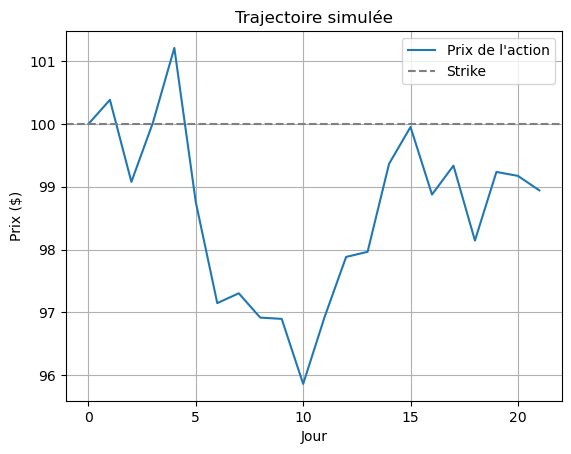

In [3]:
def simulate_stock(S0, r, sigma, days, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    Z = rng.standard_normal(days)
    inc = (r - 0.5 * sigma**2) * DT + sigma * np.sqrt(DT) * Z
    return np.concatenate(([S0], S0 * np.exp(np.cumsum(inc))))

rng = np.random.default_rng(42)
S = simulate_stock(S0, R, SIGMA, DAYS, rng)
plt.plot(S, label="Prix de l'action"); plt.axhline(K, ls="--", c="grey", label="Strike")
plt.title("Trajectoire simulée"); plt.xlabel("Jour"); plt.ylabel("Prix ($)")
plt.grid(True); plt.legend(); plt.show()

## 3. Boucle de delta-hedging

Convention de la fiche (position couverte = **long call + short Δ actions**) :

$\text{PnL}_t = (C_t - C_{t-1}) + \Delta_{t-1}(S_{t-1} - S_t) + r(\Delta_{t-1}S_{t-1} - C_{t-1})\Delta t$

Les trois termes : variation de valeur de l'option, gain/perte sur les actions shortées, intérêts sur le cash. Pour le desk (call vendu / actions achetées), le PnL est de signe opposé.

In [4]:
def delta_hedge(S, K=K, r=R, sigma=SIGMA, T=T_TOTAL, notional=NOTIONAL):
    n = len(S)
    C_, delta, gamma, vega = (np.zeros(n) for _ in range(4))
    pnl, position = np.zeros(n), np.zeros(n)

    # Jour 0 : prix, delta, mise en place de la couverture
    C_[0], delta[0], gamma[0], vega[0] = bs_greeks(S[0], K, r, T, sigma)
    position[0] = -delta[0] * notional

    for t in range(1, n):
        T_rem = T - t * DT
        C_[t], delta[t], gamma[t], vega[t] = bs_greeks(S[t], K, r, T_rem, sigma)
        pnl[t] = notional * (
            (C_[t] - C_[t-1])
            + delta[t-1] * (S[t-1] - S[t])
            + r * (delta[t-1] * S[t-1] - C_[t-1]) * DT
        )
        position[t] = -delta[t] * notional      # rebalancement quotidien

    return pd.DataFrame(dict(S=S, C=C_, delta=delta, gamma=gamma, vega=vega,
                             actions=position, pnl=pnl, pnl_cum=np.cumsum(pnl)))

res = delta_hedge(S)
res.round(3)

,S,C,delta,gamma,vega,actions,pnl,pnl_cum
0,100.000,8.916,0.579,0.020,39.104,-5792.597,0.000,0.000
1,100.385,9.121,0.587,0.019,39.022,-5866.112,-141.479,-141.479
2,99.078,8.352,0.561,0.020,38.913,-5606.835,13.974,-127.505
3,100.019,8.869,0.579,0.020,38.880,-5791.691,-69.472,-196.977
4,101.211,9.553,0.602,0.019,38.734,-6022.196,-19.235,-216.212
5,98.754,8.113,0.554,0.020,38.652,-5535.665,437.924,221.713
6,97.147,7.231,0.520,0.021,38.242,-5203.865,110.559,332.272
7,97.304,7.294,0.523,0.021,38.210,-5233.608,-153.501,178.770
8,96.917,7.074,0.515,0.021,38.019,-5150.200,-139.466,39.304
9,96.896,7.044,0.514,0.021,37.935,-5142.989,-155.868,-116.564


In [5]:
print(f"PnL total          : {res.pnl_cum.iloc[-1]:>9,.0f} $")
print(f"PnL quotidien moy. : {res.pnl[1:].mean():>9,.0f} $")
print(f"Écart-type du PnL  : {res.pnl[1:].std():>9,.0f} $")

PnL total          :    -1,049 $
PnL quotidien moy. :       -50 $
Écart-type du PnL  :       135 $


## 4. Visualisation

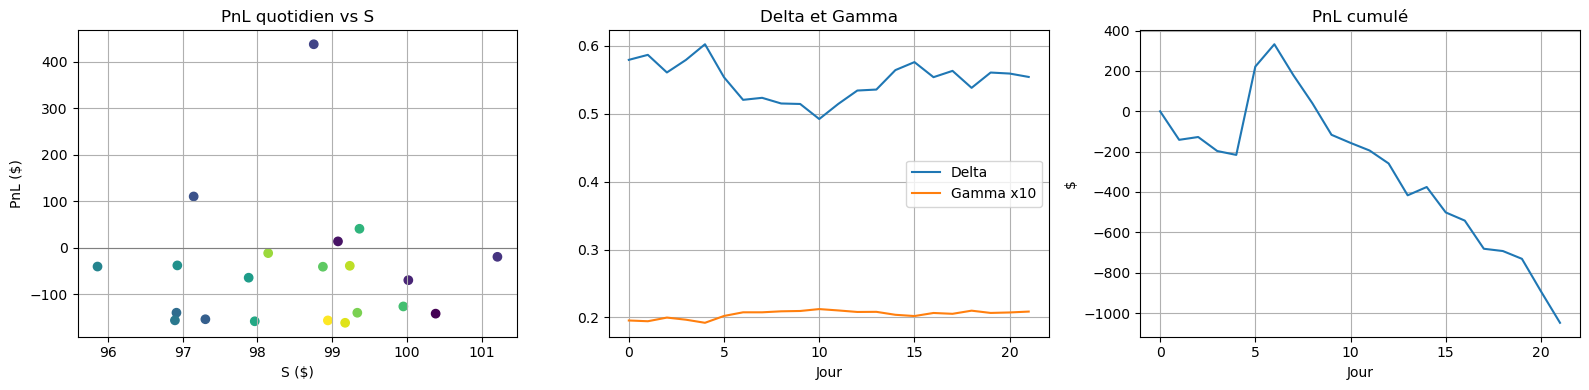

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(res.S[1:], res.pnl[1:], c=range(1, len(res)), cmap="viridis")
ax[0].axhline(0, c="grey", lw=.8); ax[0].set(title="PnL quotidien vs S", xlabel="S ($)", ylabel="PnL ($)")
ax[1].plot(res.delta, label="Delta"); ax[1].plot(res.gamma * 10, label="Gamma x10")
ax[1].set(title="Delta et Gamma", xlabel="Jour"); ax[1].legend()
ax[2].plot(res.pnl_cum); ax[2].set(title="PnL cumulé", xlabel="Jour", ylabel="$")
for a in ax: a.grid(True)
plt.tight_layout(); plt.show()

## 5. Robustesse : 5 trajectoires, puis σ = 10 % / 20 % / 40 %

Si la couverture est bonne, le PnL moyen doit rester proche de 0. Sa dispersion mesure le coût du gamma (rebalancement discret).

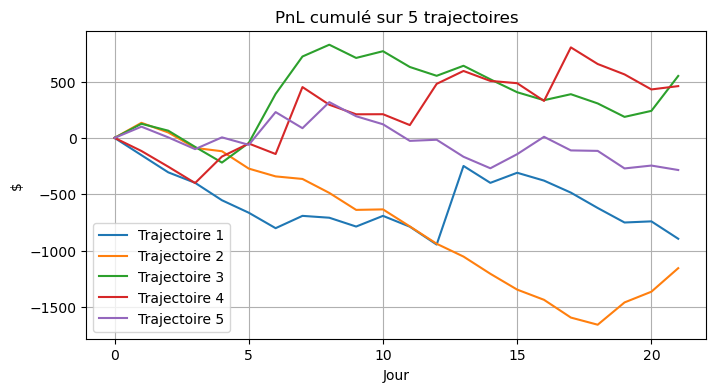

,sigma,moyenne,ecart_type,pire
0,10%,5.0,493.0,-1033.0
1,20%,-69.0,940.0,-1975.0
2,40%,26.0,1921.0,-4662.0


In [7]:
rng = np.random.default_rng(0)
plt.figure(figsize=(8, 4))
for i in range(5):
    r_ = delta_hedge(simulate_stock(S0, R, SIGMA, DAYS, rng))
    plt.plot(r_.pnl_cum, label=f"Trajectoire {i+1}")
plt.title("PnL cumulé sur 5 trajectoires"); plt.xlabel("Jour"); plt.ylabel("$")
plt.grid(True); plt.legend(); plt.show()

rows = []
for sig in (0.10, 0.20, 0.40):
    tot = [delta_hedge(simulate_stock(S0, R, sig, DAYS, rng), sigma=sig).pnl_cum.iloc[-1]
           for _ in range(500)]
    rows.append(dict(sigma=f"{sig:.0%}", moyenne=np.mean(tot), ecart_type=np.std(tot), pire=np.min(tot)))
pd.DataFrame(rows).round(0)

## 6. Conclusions

- Le PnL moyen est proche de 0 pour toutes les volatilités : la couverture neutralise bien le risque directionnel.
- La dispersion du PnL augmente avec σ : plus le sous-jacent bouge, plus le rebalancement discret coûte (**gamma drag**).
- Limites : volatilité supposée connue et constante, pas de frais de transaction, rebalancement quotidien uniquement. Pistes : vol stochastique, frais, fréquence de rebalancement, hedge du vega.